# Lateral distribution of Cherenkov light

Gammas from the zenith at fixed energies (`gamma_lateral_<E>TeV.yaml`), core at the origin, 101 telescopes in a line 0-1000 m from it.

Uses sim_telarray's true photoelectrons per pixel (`store_photoelectrons = 1`), stored for every telescope in every shower, triggered or not; telescopes with none count as 0. For each camera it takes the brightest and the 2nd-brightest pixel (the 2-pixel trigger needs two pixels above threshold). ADU = `FADC_AMPLITUDE` × p.e., without noise or pedestal.

In [1]:
import glob
from pathlib import Path

import numpy as np
from eventio import SimTelFile
from matplotlib import pyplot as plt

ENERGIES = [1, 10, 100, 1000] # [TeV]
SIMTEL_FILES = str(Path("~/panoseti/simulations/sim_output/gamma_lateral_{energy}TeV/simtel/v1/*.simtel.zst").expanduser())
OUTPUT_DIR = Path("~/panoseti/simulations/lateral").expanduser() # plots

FADC_AMPLITUDE = 16.0 # ADU per p.e. (fadc_amplitude in panoseti_simtelarray_example.cfg)
TRIGGER_THRESHOLD = 6.5 # [p.e.] discriminator_threshold, 2-pixel majority
BAND = (16, 84) # shower-to-shower spread [percentiles]

# one-hue ramp for the energy (ordered), plus a marker per energy
COLORS = {1: "#86b6ef", 10: "#3987e5", 100: "#1c5cab", 1000: "#0d366b"}
MARKERS = {1: "v", 10: "s", 100: "^", 1000: "o"}
THRESHOLD_STYLE = dict(color="#444444", linestyle="--", linewidth=1.5)

In [2]:
def pixel_maxima(simtel_files):
    """
    Brightest and 2nd-brightest pixel [p.e.] of every telescope in every shower, triggered or not.

    Returns:
        distance: (n_tel,) telescope distance from the shower core [m]
        brightest, second: (n_showers, n_tel), 0 where a telescope has no stored photoelectrons
    """
    brightest, second, distance = [], [], None
    for simtel_file in simtel_files:
        with SimTelFile(simtel_file) as f:
            tel_pos = f.header["tel_pos"]
            for event in f.iter_mc_events():
                core = np.array([event["mc_event"]["xcore"], event["mc_event"]["ycore"]])
                d = np.hypot(*(tel_pos[:, :2] - core).T)
                if distance is None:
                    distance = d
                elif not np.allclose(d, distance, atol=0.01):
                    raise ValueError(f"{simtel_file}: event {event['event_id']} has its core at {core}, not where the others are")
                b, s = np.zeros(len(tel_pos)), np.zeros(len(tel_pos))
                for index, pe in event.get("photoelectrons", {}).items(): # keyed by the telescope's index in tel_pos
                    top2 = np.partition(pe["photoelectrons"], -2)[-2:]
                    b[index], s[index] = top2[1], top2[0]
                brightest.append(b)
                second.append(s)
    return distance, np.array(brightest), np.array(second)

In [3]:
results = {}
for energy in ENERGIES:
    files = sorted(glob.glob(SIMTEL_FILES.format(energy=energy)))
    if not files:
        print(f"{energy} TeV: no files matching {SIMTEL_FILES.format(energy=energy)}, skipping")
        continue
    results[energy] = pixel_maxima(files)
    print(f"{energy} TeV: {len(files)} runs, {len(results[energy][1])} showers")

1 TeV: 100 runs, 1000 showers


10 TeV: 100 runs, 1000 showers


100 TeV: 100 runs, 1000 showers


1000 TeV: 100 runs, 1000 showers


## Mean per pixel

Average over all showers, like the reference figure. Error bars: standard error of the mean (mostly smaller than the markers).

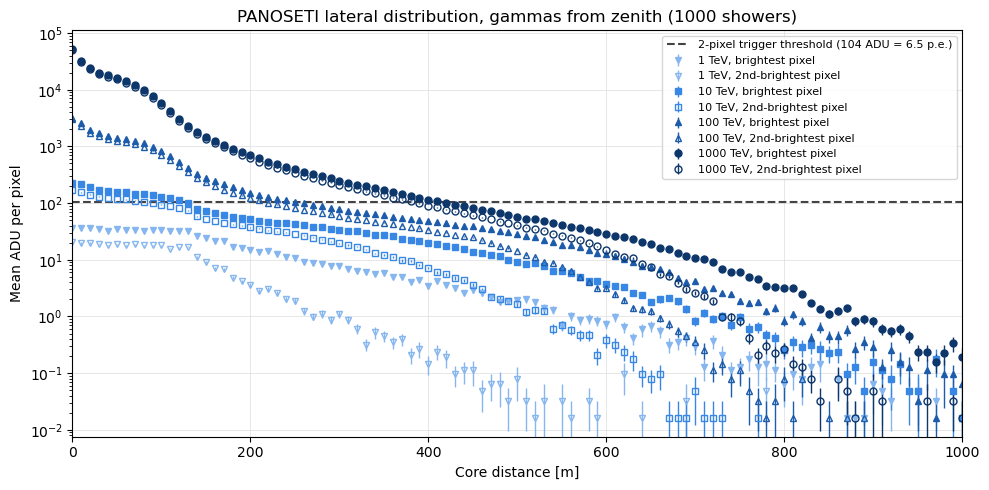

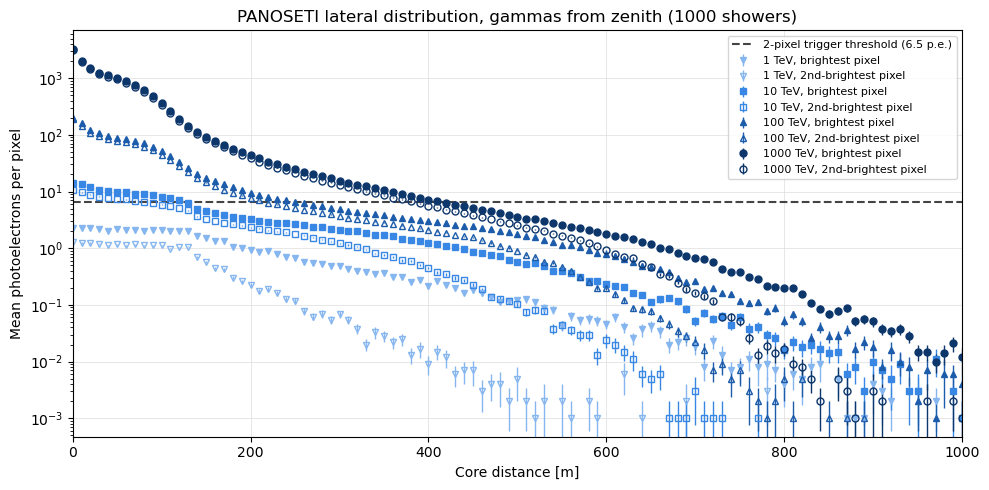

In [4]:
def plot_mean(scale, ylabel, threshold_label):
    fig, ax = plt.subplots(figsize=(10, 5))
    for energy, (distance, brightest, second) in results.items():
        n = len(brightest)
        kw = dict(color=COLORS[energy], marker=MARKERS[energy], markersize=5, linestyle="none", elinewidth=1)
        for pixel, values, face in [("brightest", brightest, COLORS[energy]), ("2nd-brightest", second, "none")]:
            ax.errorbar(distance, scale * values.mean(axis=0), yerr=scale * values.std(axis=0, ddof=1) / np.sqrt(n),
                        markerfacecolor=face, label=f"{energy} TeV, {pixel} pixel", **kw)
    ax.axhline(scale * TRIGGER_THRESHOLD, label=threshold_label, **THRESHOLD_STYLE)
    ax.set_yscale("log")
    ax.set_xlim(0, 1000)
    ax.set_xlabel("Core distance [m]")
    ax.set_ylabel(ylabel)
    ax.set_title(f"PANOSETI lateral distribution, gammas from zenith ({len(brightest)} showers)")
    ax.grid(True, which="major", color="#dddddd", linewidth=0.5)
    ax.legend(fontsize=8, loc="upper right")
    fig.tight_layout()
    return fig

for name, scale, ylabel, threshold_label in [
    ("adu", FADC_AMPLITUDE, "Mean ADU per pixel", f"2-pixel trigger threshold ({FADC_AMPLITUDE * TRIGGER_THRESHOLD:g} ADU = {TRIGGER_THRESHOLD:g} p.e.)"),
    ("pe", 1.0, "Mean photoelectrons per pixel", f"2-pixel trigger threshold ({TRIGGER_THRESHOLD:g} p.e.)"),
]:
    plot_mean(scale, ylabel, threshold_label).savefig(OUTPUT_DIR / f"lateral_distribution_{name}.png", dpi=300)
    plt.show()

## Shower-to-shower spread

At each distance, the median (lines) and the 16-84% band (`BAND`, shaded) of the per-shower pixel values, all energies together: brightest pixel on the left, 2nd-brightest on the right. Where a band straddles the threshold, whether a camera triggers depends on the shower, not just the distance.

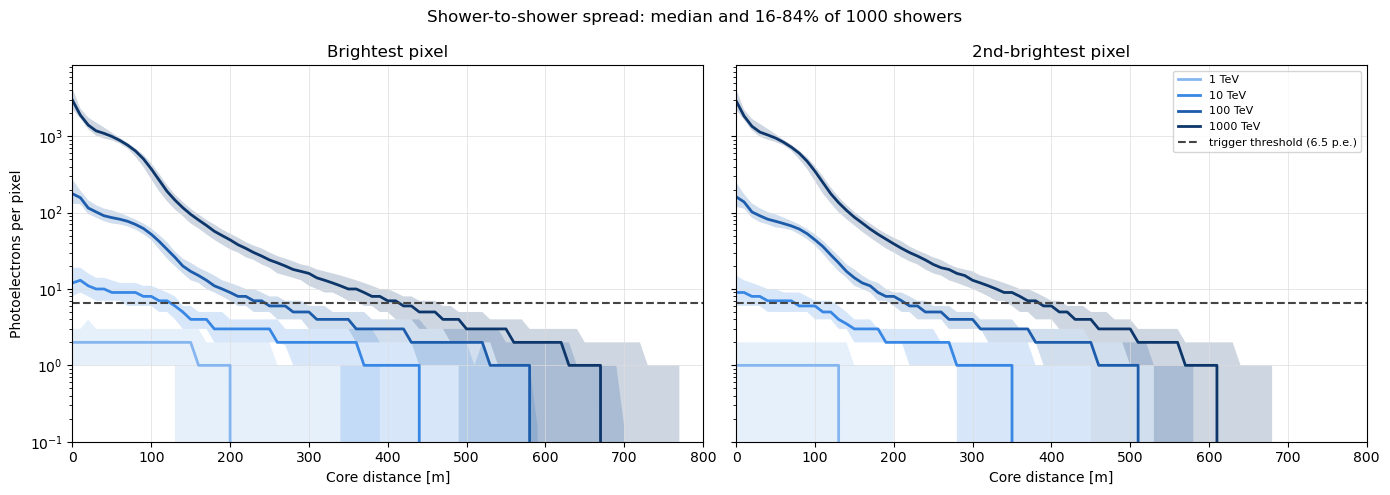

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, pixel, index in [(axes[0], "Brightest", 1), (axes[1], "2nd-brightest", 2)]:
    for energy, result in results.items():
        distance, values = result[0], result[index]
        low, median, high = np.percentile(values, [BAND[0], 50, BAND[1]], axis=0)
        ax.fill_between(distance, low, high, color=COLORS[energy], alpha=0.2, linewidth=0)
        ax.plot(distance, median, color=COLORS[energy], linewidth=2, label=f"{energy} TeV")
    ax.axhline(TRIGGER_THRESHOLD, label=f"trigger threshold ({TRIGGER_THRESHOLD:g} p.e.)", **THRESHOLD_STYLE)
    ax.set_title(f"{pixel} pixel")
    ax.set_xlabel("Core distance [m]")
    ax.grid(True, which="major", color="#dddddd", linewidth=0.5)
axes[0].set_ylabel("Photoelectrons per pixel")
axes[1].legend(fontsize=8, loc="upper right")
ax.set_yscale("log")
ax.set_xlim(0, 800)
ax.set_ylim(0.1, 2 * max(np.percentile(brightest, BAND[1], axis=0).max() for _, brightest, _ in results.values()))
fig.suptitle(f"Shower-to-shower spread: median and {BAND[0]}-{BAND[1]}% of {len(brightest)} showers")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "lateral_distribution_spread.png", dpi=300)
plt.show()

## Fraction of showers above threshold

Fraction of showers whose brightest (filled) and 2nd-brightest (open) pixel reach the threshold. The 2nd-brightest curve is only an approximation of the trigger probability: the real trigger also needs both pixels in the same quabo and within the same 5 ns gate.

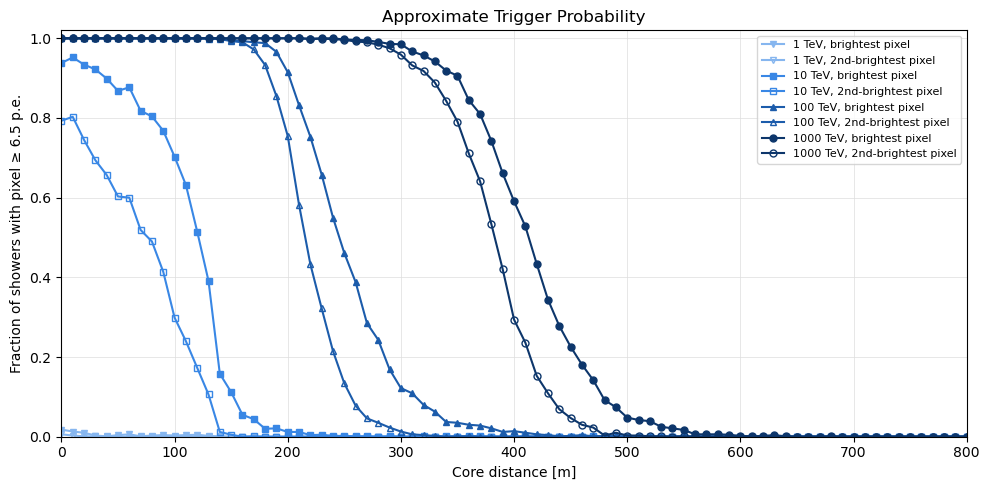

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))
for energy, (distance, brightest, second) in results.items():
    for pixel, values, face in [("brightest", brightest, COLORS[energy]), ("2nd-brightest", second, "none")]:
        ax.plot(distance, (values >= TRIGGER_THRESHOLD).mean(axis=0), color=COLORS[energy], marker=MARKERS[energy], markersize=5,
                markerfacecolor=face, label=f"{energy} TeV, {pixel} pixel")
ax.set_xlim(0, 800)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Core distance [m]")
ax.set_ylabel(f"Fraction of showers with pixel ≥ {TRIGGER_THRESHOLD:g} p.e.")
ax.grid(True, which="major", color="#dddddd", linewidth=0.5)
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Approximate Trigger Probability")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "lateral_distribution_fraction.png", dpi=300)
plt.show()